# U.S. Rental Property Market Analysis

**Questions**
1. How have home prices and rents changed across the U.S. over the last 10 years?
2. Where is buying expensive compared with renting (price-to-rent ratio)?
3. Which market factors are associated with faster home-value growth?
4. In which cities would a typical rental property make money each month?

**Data:** Zillow Research, real public data through September 2026, for the **100 largest U.S. metros**.
- **ZHVI:** Zillow Home Value Index (typical home value)
- **ZORI:** Zillow Observed Rent Index (typical monthly rent)

**Tools:** SQL (SQLite) for joins and calculations · Python for regression and charts · Excel for the
cash-flow model (`rental_market_analysis.xlsx`)

In [ ]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def load_zillow(path, value_name):
    """Zillow files are wide -> one column per month. Reshape to one row per metro per month."""
    wide = pd.read_csv(path)
    month_cols = [c for c in wide.columns if c[:2] in ("19", "20")]
    long = wide.melt(id_vars=["RegionID", "SizeRank", "RegionName", "RegionType", "StateName"],
                     value_vars=month_cols, var_name="month", value_name=value_name)
    long["month"] = long["month"].str[:7]          # '2026-09-30' -> '2026-09'
    return long.dropna(subset=[value_name])

homes = load_zillow("data/Metro_zhvi.csv", "home_value")
rents = load_zillow("data/Metro_zori.csv", "rent")

con = sqlite3.connect(":memory:")
homes.to_sql("home_values", con, index=False)
rents.to_sql("rents", con, index=False)

def sql(query):
    return pd.read_sql(query, con)

LATEST = sql("SELECT MAX(month) AS m FROM rents")["m"][0]
YEAR_AGO = f"{int(LATEST[:4]) - 1}{LATEST[4:]}"
FIVE_YEARS_AGO = f"{int(LATEST[:4]) - 5}{LATEST[4:]}"
print(f"Home values: {len(homes):,} rows | Rents: {len(rents):,} rows")
print(f"Latest month: {LATEST} | 1 year ago: {YEAR_AGO} | 5 years ago: {FIVE_YEARS_AGO}")

Home values: 238,029 rows | Rents: 53,977 rows
Latest month: 2026-09 | 1 year ago: 2025-09 | 5 years ago: 2021-09


## 1. National trend: home prices vs. rents (SQL)

In [2]:
national = sql(f"""
    SELECT h.month,
           ROUND(h.home_value) AS home_value,
           ROUND(r.rent)       AS rent
    FROM home_values h
    JOIN rents r ON r.RegionID = h.RegionID AND r.month = h.month
    WHERE h.RegionType = 'country'
      AND SUBSTR(h.month, 6, 2) = '{LATEST[5:]}'      -- same month each year
    ORDER BY h.month
""")
first = national.iloc[0]
national["home_value_index"] = (national["home_value"] / first["home_value"] * 100).round(1)
national["rent_index"] = (national["rent"] / first["rent"] * 100).round(1)
print(national.to_string(index=False))

  month  home_value   rent  home_value_index  rent_index
2015-09    195177.0 1181.0             100.0       100.0
2016-09    206363.0 1225.0             105.7       103.7
2017-09    219301.0 1276.0             112.4       108.0
2018-09    233552.0 1327.0             119.7       112.4
2019-09    243849.0 1383.0             124.9       117.1
2020-09    259663.0 1410.0             133.0       119.4
2021-09    305989.0 1590.0             156.8       134.6
2022-09    348056.0 1748.0             178.3       148.0
2023-09    351976.0 1797.0             180.3       152.2
2024-09    361483.0 1845.0             185.2       156.2
2025-09    361859.0 1881.0             185.4       159.3
2026-09    366157.0 1932.0             187.6       163.6


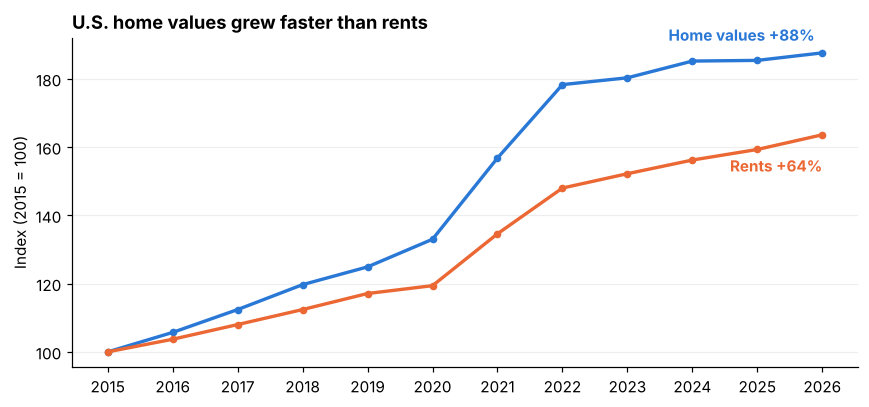

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
years = national["month"].str[:4]
ax.plot(years, national["home_value_index"], color="#2a78d6", lw=2.2, marker="o", ms=4)
ax.plot(years, national["rent_index"], color="#eb6834", lw=2.2, marker="o", ms=4)
ax.annotate(f"Home values +{national['home_value_index'].iloc[-1]-100:.0f}%", (len(years)-1, national["home_value_index"].iloc[-1]),
            xytext=(-5, 8), textcoords="offset points", ha="right", color="#2a78d6", fontweight="bold")
ax.annotate(f"Rents +{national['rent_index'].iloc[-1]-100:.0f}%", (len(years)-1, national["rent_index"].iloc[-1]),
            xytext=(0, -24), textcoords="offset points", ha="right", color="#eb6834", fontweight="bold")
ax.set_ylabel(f"Index ({years.iloc[0]} = 100)")
ax.set_title("U.S. home values grew faster than rents", loc="left", fontweight="bold")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="y", color="#eeeeee")
plt.tight_layout()
plt.savefig("charts/1_national_trend.png", dpi=150)
plt.show()

## 2. Metro snapshot: prices, rents and growth (SQL)

For each metro, pull the value **now**, **1 year ago** and **5 years ago**, then compute:
- **Price-to-rent ratio** = home value ÷ yearly rent. Higher means buying is expensive relative to renting
  (above ~20 is generally considered expensive to buy).
- **1-year and 5-year growth** for both home values and rents.

Sample: the 100 largest metros with complete rent data.

In [4]:
metros = sql(f"""
    WITH h AS (
        SELECT RegionID, RegionName AS metro, StateName AS state, SizeRank AS size_rank,
               MAX(CASE WHEN month = '{LATEST}'         THEN home_value END) AS value_now,
               MAX(CASE WHEN month = '{YEAR_AGO}'       THEN home_value END) AS value_1y,
               MAX(CASE WHEN month = '{FIVE_YEARS_AGO}' THEN home_value END) AS value_5y
        FROM home_values WHERE RegionType = 'msa'
        GROUP BY RegionID
    ),
    r AS (
        SELECT RegionID,
               MAX(CASE WHEN month = '{LATEST}'         THEN rent END) AS rent_now,
               MAX(CASE WHEN month = '{YEAR_AGO}'       THEN rent END) AS rent_1y,
               MAX(CASE WHEN month = '{FIVE_YEARS_AGO}' THEN rent END) AS rent_5y
        FROM rents WHERE RegionType = 'msa'
        GROUP BY RegionID
    )
    SELECT h.metro, h.state, h.size_rank,
           ROUND(h.value_now) AS home_value, ROUND(r.rent_now) AS monthly_rent,
           ROUND(h.value_now / (r.rent_now * 12), 1)          AS price_to_rent,
           ROUND(h.value_5y  / (r.rent_5y  * 12), 1)          AS price_to_rent_5y_ago,
           ROUND((h.value_now / h.value_1y - 1) * 100, 1)     AS home_growth_1y_pct,
           ROUND((h.value_now / h.value_5y - 1) * 100, 1)     AS home_growth_5y_pct,
           ROUND((r.rent_now  / r.rent_1y  - 1) * 100, 1)     AS rent_growth_1y_pct,
           ROUND((r.rent_now  / r.rent_5y  - 1) * 100, 1)     AS rent_growth_5y_pct,
           h.value_1y, h.value_5y, r.rent_1y, r.rent_5y
    FROM h JOIN r USING (RegionID)
    WHERE r.rent_now IS NOT NULL AND r.rent_5y IS NOT NULL AND h.value_5y IS NOT NULL
    ORDER BY h.size_rank
    LIMIT 100
""")

# Add Census region from the state code
REGION = {**dict.fromkeys("CT ME MA NH RI VT NJ NY PA".split(), "Northeast"),
          **dict.fromkeys("IL IN MI OH WI IA KS MN MO NE ND SD".split(), "Midwest"),
          **dict.fromkeys("DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX".split(), "South"),
          **dict.fromkeys("AZ CO ID MT NV NM UT WY AK CA HI OR WA".split(), "West")}
metros.insert(2, "region", metros["state"].map(REGION))
print(f"{len(metros)} metros, {metros['region'].isna().sum()} without a region")
print(metros.iloc[:, :12].head(10).to_string(index=False))

100 metros, 0 without a region
           metro state    region  size_rank  home_value  monthly_rent  price_to_rent  price_to_rent_5y_ago  home_growth_1y_pct  home_growth_5y_pct  rent_growth_1y_pct  rent_growth_5y_pct
    New York, NY    NY Northeast          1    730949.0        3546.0           17.2                  18.1                 4.9                27.7                 4.2                34.5
 Los Angeles, CA    CA      West          2    950020.0        2929.0           27.0                  26.9                 1.3                19.2                 1.8                18.7
     Chicago, IL    IL   Midwest          3    355650.0        2163.0           13.7                  14.3                 5.0                27.9                 4.7                33.2
      Dallas, TX    TX     South          4    358242.0        1659.0           18.0                  17.8                -2.0                10.8                 0.7                 9.6
     Houston, TX    TX     South  

In [5]:
cols = ["metro", "home_value", "monthly_rent", "price_to_rent"]
print("MOST EXPENSIVE TO BUY vs. RENT (highest price-to-rent)")
print(metros.nlargest(5, "price_to_rent")[cols].to_string(index=False))
print("\nCHEAPEST TO BUY vs. RENT (lowest price-to-rent)")
print(metros.nsmallest(5, "price_to_rent")[cols].to_string(index=False))
print(f"\nMedian price-to-rent ratio: {metros['price_to_rent'].median():.1f}  "
      f"(5 years ago: {metros['price_to_rent_5y_ago'].median():.1f})")
print(f"Metros above 20 (expensive to buy): {(metros['price_to_rent'] > 20).sum()} of {len(metros)}")

print("\nBY REGION")
by_region = metros.groupby("region").agg(
    metros=("metro", "count"),
    median_home_value=("home_value", "median"),
    median_rent=("monthly_rent", "median"),
    median_price_to_rent=("price_to_rent", "median"),
    home_growth_5y_pct=("home_growth_5y_pct", "median"),
    rent_growth_5y_pct=("rent_growth_5y_pct", "median"),
).round(1)
print(by_region.to_string())

MOST EXPENSIVE TO BUY vs. RENT (highest price-to-rent)
             metro  home_value  monthly_rent  price_to_rent
      San Jose, CA   1523615.0        3812.0           33.3
Salt Lake City, UT    558850.0        1644.0           28.3
 San Francisco, CA   1120379.0        3445.0           27.1
   Los Angeles, CA    950020.0        2929.0           27.0
       Seattle, WA    720147.0        2250.0           26.7

CHEAPEST TO BUY vs. RENT (lowest price-to-rent)
         metro  home_value  monthly_rent  price_to_rent
   Jackson, MS    212335.0        1470.0           12.0
   El Paso, TX    233011.0        1521.0           12.8
Pittsburgh, PA    228201.0        1467.0           13.0
    Toledo, OH    202056.0        1264.0           13.3
  Columbia, SC    252979.0        1557.0           13.5

Median price-to-rent ratio: 17.2  (5 years ago: 17.1)
Metros above 20 (expensive to buy): 26 of 100

BY REGION
           metros  median_home_value  median_rent  median_price_to_rent  home_growth_5y_

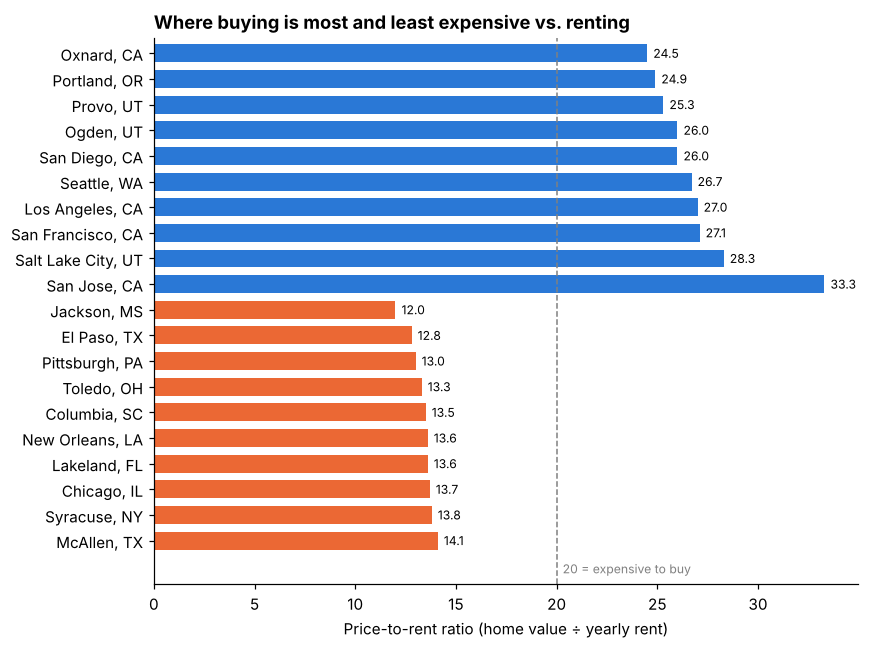

In [6]:
# Chart: 10 highest and 10 lowest price-to-rent ratios
top = metros.nlargest(10, "price_to_rent")
bottom = metros.nsmallest(10, "price_to_rent").iloc[::-1]
show = pd.concat([bottom, top])
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#eb6834"] * 10 + ["#2a78d6"] * 10
ax.barh(show["metro"], show["price_to_rent"], color=colors, height=0.7)
for y, v in enumerate(show["price_to_rent"]):
    ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=8)
ax.axvline(20, color="gray", ls="--", lw=1)
ax.text(20.3, -1.1, "20 = expensive to buy", fontsize=8, color="gray", va="center")
ax.set_ylim(-1.7, 19.6)
ax.set_xlabel("Price-to-rent ratio (home value ÷ yearly rent)")
ax.set_title("Where buying is most and least expensive vs. renting", loc="left", fontweight="bold")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("charts/2_price_to_rent.png", dpi=150)
plt.show()

## 3. Regression: what is associated with home-value growth?

**Model** (one row per metro, 5-year change):

home value growth = rent growth + starting price-to-rent ratio + region

- **Rent growth:** do home prices rise where rents rise? (demand)
- **Starting price-to-rent:** did already-expensive markets grow less? (affordability limit)
- **Region:** compared with the Northeast

This shows **association, not cause**: other factors (jobs, migration, new construction) also matter.

In [7]:
def ols(y, X, names):
    """Ordinary least squares with standard errors, p-values and R-squared."""
    X = np.column_stack([np.ones(len(y)), X])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    n, k = X.shape
    sigma2 = resid @ resid / (n - k)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), n - k)
    r2 = 1 - resid @ resid / ((y - y.mean()) @ (y - y.mean()))
    table = pd.DataFrame({"coefficient": beta, "std_error": se, "p_value": p}, index=["intercept"] + names)
    return table.round(3), r2

d = pd.get_dummies(metros["region"], dtype=float).drop(columns="Northeast")
X = np.column_stack([metros["rent_growth_5y_pct"], metros["price_to_rent_5y_ago"], d])
names = ["rent_growth_5y_pct", "price_to_rent_5y_ago"] + [f"region_{c}" for c in d.columns]
model, r2 = ols(metros["home_growth_5y_pct"].values, X, names)
print(model.to_string())
print(f"\nR-squared: {r2:.2f}  (share of the variation in home-value growth explained)")
print(f"Metros: {len(metros)}")

                      coefficient  std_error  p_value
intercept                  17.371      4.680    0.000
rent_growth_5y_pct          0.852      0.094    0.000
price_to_rent_5y_ago       -0.608      0.195    0.002
region_Midwest             -4.401      2.035    0.033
region_South               -4.851      1.991    0.017
region_West                -5.707      2.581    0.029

R-squared: 0.72  (share of the variation in home-value growth explained)
Metros: 100


- Each extra 1 point of 5-year rent growth goes with +0.85 points of home-value growth.
- Each extra 1 point of starting price-to-rent ratio goes with -0.61 points of home-value growth.
- Midwest metros grew -4.4 points vs. the Northeast (p = 0.033).
- South metros grew -4.9 points vs. the Northeast (p = 0.017).
- West metros grew -5.7 points vs. the Northeast (p = 0.029).


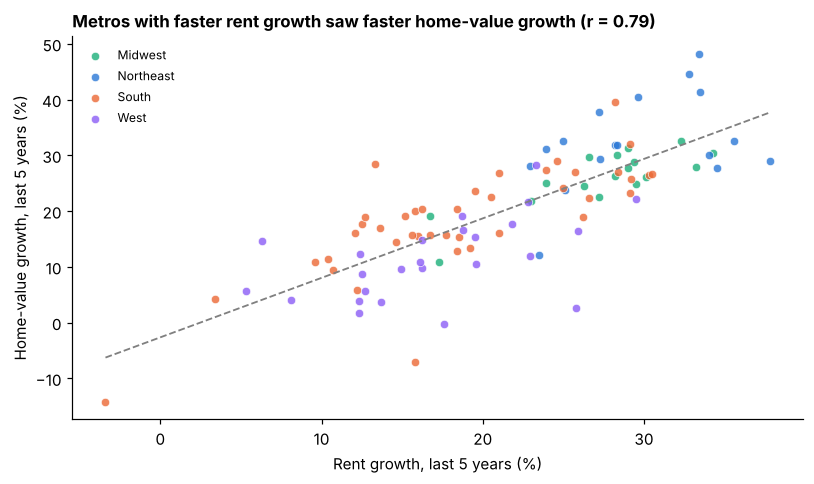

In [8]:
b_rent = model.loc["rent_growth_5y_pct", "coefficient"]
b_ptr = model.loc["price_to_rent_5y_ago", "coefficient"]
print(f"- Each extra 1 point of 5-year rent growth goes with {b_rent:+.2f} points of home-value growth.")
print(f"- Each extra 1 point of starting price-to-rent ratio goes with {b_ptr:+.2f} points of home-value growth.")
for c in d.columns:
    r = model.loc[f"region_{c}"]
    print(f"- {c} metros grew {r['coefficient']:+.1f} points vs. the Northeast (p = {r['p_value']:.3f}).")

# Scatter: rent growth vs home-value growth
fig, ax = plt.subplots(figsize=(7.5, 4.5))
palette = {"Northeast": "#2a78d6", "Midwest": "#1baf7a", "South": "#eb6834", "West": "#8b5cf6"}
for region, g in metros.groupby("region"):
    ax.scatter(g["rent_growth_5y_pct"], g["home_growth_5y_pct"], s=30, alpha=0.8,
               color=palette[region], label=region, edgecolor="white", lw=0.5)
slope, intercept, r, p, _ = stats.linregress(metros["rent_growth_5y_pct"], metros["home_growth_5y_pct"])
xs = np.linspace(metros["rent_growth_5y_pct"].min(), metros["rent_growth_5y_pct"].max(), 50)
ax.plot(xs, intercept + slope * xs, color="gray", lw=1.2, ls="--")
ax.set_xlabel("Rent growth, last 5 years (%)")
ax.set_ylabel("Home-value growth, last 5 years (%)")
ax.set_title(f"Metros with faster rent growth saw faster home-value growth (r = {r:.2f})",
             loc="left", fontweight="bold", fontsize=11)
ax.legend(frameon=False, fontsize=8)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("charts/3_rent_vs_home_growth.png", dpi=150)
plt.show()

## 4. Would a rental property make money? (monthly cash flow)

Buy a typical home in each metro, rent it at the typical rent. Assumptions (all adjustable in the Excel model):

| Assumption | Value |
|---|---|
| Mortgage rate (30-yr fixed) | 7.18% (Freddie Mac survey, Nov 5, 2026) |
| Down payment | 20% |
| Property tax | 1.1% of value per year |
| Insurance | 0.5% of value per year |
| Maintenance | 1% of value per year |
| Vacancy | 5% of rent |
| Property management | 8% of rent |

In [9]:
RATE, DOWN, YEARS = 0.0718, 0.20, 30
TAX, INSURANCE, MAINTENANCE = 0.011, 0.005, 0.01
VACANCY, MANAGEMENT = 0.05, 0.08

def monthly_cash_flow(home_value, rent, rate=RATE):
    loan = home_value * (1 - DOWN)
    r = rate / 12
    mortgage = loan * r / (1 - (1 + r) ** (-YEARS * 12))
    costs = home_value * (TAX + INSURANCE + MAINTENANCE) / 12 + rent * (VACANCY + MANAGEMENT)
    return rent - mortgage - costs

metros["monthly_cash_flow"] = monthly_cash_flow(metros["home_value"], metros["monthly_rent"]).round(0)
positive = metros[metros["monthly_cash_flow"] > 0]
print(f"Metros with positive monthly cash flow at {RATE:.2%}: {len(positive)} of {len(metros)}")
print(f"Median monthly cash flow: ${metros['monthly_cash_flow'].median():,.0f}")

print("\nBEST 5")
print(metros.nlargest(5, "monthly_cash_flow")[["metro", "home_value", "monthly_rent", "price_to_rent", "monthly_cash_flow"]].to_string(index=False))
print("\nWORST 5")
print(metros.nsmallest(5, "monthly_cash_flow")[["metro", "home_value", "monthly_rent", "price_to_rent", "monthly_cash_flow"]].to_string(index=False))

print("\nBREAK-EVEN MORTGAGE RATE: the highest rate at which rent still covers all costs")
grid = np.arange(0, 0.10001, 0.0001)
def break_even_rate(value, rent):
    ok = [r for r in grid if monthly_cash_flow(value, rent, r) > 0]
    return max(ok) if ok else np.nan
metros["break_even_rate"] = [break_even_rate(v, r) for v, r in zip(metros["home_value"], metros["monthly_rent"])]
never = metros["break_even_rate"].isna().sum()
print(f"Metros with negative cash flow even at a 0% rate: {never} "
      "(rent can't cover principal repayment plus taxes, insurance and upkeep)")
print("Metros with the highest break-even rate:")
be = metros.nlargest(5, "break_even_rate")[["metro", "price_to_rent", "break_even_rate"]].copy()
be["break_even_rate"] = be["break_even_rate"].map("{:.2%}".format)
print(be.to_string(index=False))
for rate in [0.03, 0.04, 0.05, 0.06]:
    n = (monthly_cash_flow(metros["home_value"], metros["monthly_rent"], rate) > 0).sum()
    print(f"  Cash-flow positive at {rate:.0%}: {n} metros")

Metros with positive monthly cash flow at 7.18%: 0 of 100
Median monthly cash flow: $-1,239

BEST 5
         metro  home_value  monthly_rent  price_to_rent  monthly_cash_flow
   Jackson, MS    212335.0        1470.0           12.0             -332.0
    Toledo, OH    202056.0        1264.0           13.3             -433.0
   El Paso, TX    233011.0        1521.0           12.8             -444.0
Pittsburgh, PA    228201.0        1467.0           13.0             -455.0
   McAllen, TX    188971.0        1119.0           14.1             -460.0

WORST 5
            metro  home_value  monthly_rent  price_to_rent  monthly_cash_flow
     San Jose, CA   1523615.0        3812.0           33.3            -8242.0
San Francisco, CA   1120379.0        3445.0           27.1            -5502.0
  Los Angeles, CA    950020.0        2929.0           27.0            -4659.0
    San Diego, CA    926961.0        2967.0           26.0            -4451.0
       Oxnard, CA    869803.0        2955.0        

In [10]:
# Save the metro table for the Excel model (and Tableau, if you want a map)
metros.to_csv("data/metro_summary.csv", index=False)
print("Saved data/metro_summary.csv")

Saved data/metro_summary.csv


## Key findings

See the printed results above. The summary in `README.md` lists the final numbers.

## Limitations
- **Typical values, not specific homes:** ZHVI and ZORI describe a mid-priced home and a typical rent, which
  may be different kinds of homes (rents include apartments).
- **One national assumption set:** property tax and insurance vary a lot by state (Texas taxes and Florida
  insurance are much higher)
- **Regression shows association, not cause**, on 100 data points.
- Cash flow ignores appreciation and tax benefits, which are a big part of real investor returns.